In [1]:
# Job Acceptance Prediction System
# Data Science Project
# Name: R. Kaviya

In [2]:
print("Job Acceptance Prediction System")

Job Acceptance Prediction System


In [3]:
import pandas as pd
import numpy as np

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
df = pd.read_csv("HR_Job_Placement_Dataset.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (51500, 26)


,age_years,gender,ssc_percentage,hsc_percentage,degree_percentage,degree_specialization,technical_score,aptitude_score,communication_score,skills_match_percentage,...,expected_ctc_lpa,company_tier,job_role_match,competition_level,bond_requirement,notice_period_days,layoff_history,employment_gap_months,relocation_willingness,status
0,27,Male,65.061656,83.842578,75.856526,Computer Science,58.221909,89.566305,64.474484,79.548913,...,5.805850,Tier 3,Not Matched,Medium,Not Required,15.0,No,18.0,Not Willing,Not Placed
1,24,Male,67.885626,64.973305,73.093588,Electronics,71.927978,54.591971,61.077306,73.316134,...,10.807739,Tier 1,Matched,High,Required,0.0,NaN,NaN,Not Willing,Not Placed
2,33,Female,73.892471,68.834121,90.196460,Information Technology,72.445041,58.587088,79.494739,75.466980,...,5.476839,Tier 3,Not Matched,Low,Not Required,0.0,No,3.0,Not Willing,Placed
3,31,Male,74.145568,76.255126,75.586731,Mechanical,78.855676,61.022065,53.740386,73.676449,...,9.980580,Tier 2,Matched,Low,Not Required,0.0,Yes,6.0,NaN,Not Placed
4,28,Male,60.475937,65.786336,80.801010,Information Technology,68.286776,65.713731,61.438314,88.994847,...,8.921233,Tier 2,Matched,Medium,Not Required,0.0,No,3.0,Willing,Not Placed


In [5]:
print("Dataset Information:")
df.info()

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 51500 entries, 0 to 51499
Data columns (total 26 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   age_years                  51500 non-null  int64  
 1   gender                     51500 non-null  str    
 2   ssc_percentage             48919 non-null  float64
 3   hsc_percentage             49435 non-null  float64
 4   degree_percentage          51500 non-null  float64
 5   degree_specialization      51500 non-null  str    
 6   technical_score            51500 non-null  float64
 7   aptitude_score             51500 non-null  float64
 8   communication_score        51500 non-null  float64
 9   skills_match_percentage    51500 non-null  float64
 10  certifications_count       51500 non-null  int64  
 11  internship_experience      51500 non-null  str    
 12  years_of_experience        51500 non-null  int64  
 13  career_switch_willingness  43034 non

In [6]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
age_years                       0
gender                          0
ssc_percentage               2581
hsc_percentage               2065
degree_percentage               0
degree_specialization           0
technical_score                 0
aptitude_score                  0
communication_score             0
skills_match_percentage         0
certifications_count            0
internship_experience           0
years_of_experience             0
career_switch_willingness    8466
relevant_experience          8426
previous_ctc_lpa                0
expected_ctc_lpa                0
company_tier                    0
job_role_match               6131
competition_level               0
bond_requirement                0
notice_period_days           1582
layoff_history               8467
employment_gap_months        1097
relocation_willingness       8475
status                          0
dtype: int64


In [7]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 1376


In [8]:
print("Status Distribution:")
print(df["status"].value_counts())

print("\nStatus Percentage:")
print(df["status"].value_counts(normalize=True) * 100)

Status Distribution:
status
Not Placed    35921
Placed        15579
Name: count, dtype: int64

Status Percentage:
status
Not Placed    69.749515
Placed        30.250485
Name: proportion, dtype: float64


In [9]:
df.describe()

,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,previous_ctc_lpa,expected_ctc_lpa,notice_period_days,employment_gap_months
count,51500.000000,48919.000000,49435.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,51500.000000,49918.000000,50403.000000
mean,27.505456,70.002505,72.060636,74.010825,68.027499,64.005715,66.106692,73.937491,1.400136,1.494117,4.844616,8.002649,20.095457,3.056187
std,4.025385,7.976314,7.916654,6.945579,11.855145,9.922397,9.907488,11.794258,1.184387,1.375508,2.125294,3.133792,24.852660,4.431784
min,21.000000,50.000000,50.000000,55.000000,40.000000,40.000000,45.000000,45.000000,0.000000,0.000000,1.000000,3.000000,0.000000,0.000000
25%,24.000000,64.574733,66.720058,69.305041,59.935988,57.204237,59.252271,65.851924,1.000000,0.000000,3.325635,5.672655,0.000000,0.000000
50%,27.000000,69.971210,72.014383,73.998187,67.986042,63.972079,66.033268,74.001772,1.000000,1.000000,4.807598,7.857337,15.000000,0.000000
75%,31.000000,75.389057,77.389894,78.707827,76.049235,70.727134,72.840985,82.112773,2.000000,2.000000,6.297570,10.093509,30.000000,6.000000
max,34.000000,95.000000,95.000000,95.000000,100.000000,100.000000,100.000000,100.000000,8.000000,5.000000,13.844566,26.524634,90.000000,18.000000


In [10]:
categorical_columns = df.select_dtypes(include="object").columns

for column in categorical_columns:
    print("\n", column)
    print(df[column].value_counts())


 gender
gender
Female    24379
Male      24028
male       1549
female     1544
Name: count, dtype: int64

 degree_specialization
degree_specialization
Others                    10463
Electronics               10358
Information Technology    10298
Computer Science          10210
Mechanical                10171
Name: count, dtype: int64

 internship_experience
internship_experience
No      25607
Yes     23327
 no      1341
yes      1225
Name: count, dtype: int64

 career_switch_willingness
career_switch_willingness
Not Willing    28479
Willing        14555
Name: count, dtype: int64

 relevant_experience
relevant_experience
Relevant        26305
Not Relevant    16769
Name: count, dtype: int64

 company_tier
company_tier
Tier 1     19046
Tier 2     18301
Tier 3     12061
Tier 1       832
Tier 2       755
Tier 3       505
Name: count, dtype: int64

 job_role_match
job_role_match
Matched        33456
Not Matched    11913
Name: count, dtype: int64

 competition_level
competition_level
Low   

C:\Users\ELCOT\AppData\Local\Temp\ipykernel_6312\3922924258.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [11]:
df_clean = df.copy()

categorical_columns = df_clean.select_dtypes(include="str").columns

for column in categorical_columns:
    df_clean[column] = df_clean[column].str.strip().str.title()

print("Categorical values standardized successfully!")

Categorical values standardized successfully!


In [12]:
print("Duplicate rows before removal:", df_clean.duplicated().sum())

Duplicate rows before removal: 1500


In [13]:
df_clean = df_clean.drop_duplicates()

print("Duplicates removed successfully!")
print("New dataset shape:", df_clean.shape)
print("Remaining duplicates:", df_clean.duplicated().sum())

Duplicates removed successfully!
New dataset shape: (50000, 26)
Remaining duplicates: 0


In [14]:
print("Missing Values After Duplicate Removal:")
print(df_clean.isnull().sum())

Missing Values After Duplicate Removal:
age_years                       0
gender                          0
ssc_percentage               2500
hsc_percentage               2000
degree_percentage               0
degree_specialization           0
technical_score                 0
aptitude_score                  0
communication_score             0
skills_match_percentage         0
certifications_count            0
internship_experience           0
years_of_experience             0
career_switch_willingness    8224
relevant_experience          8183
previous_ctc_lpa                0
expected_ctc_lpa                0
company_tier                    0
job_role_match               5949
competition_level               0
bond_requirement                0
notice_period_days           1532
layoff_history               8234
employment_gap_months        1071
relocation_willingness       8227
status                          0
dtype: int64


In [15]:
numeric_columns = [
    "ssc_percentage",
    "hsc_percentage",
    "notice_period_days",
    "employment_gap_months"
]

categorical_missing_columns = [
    "career_switch_willingness",
    "relevant_experience",
    "job_role_match",
    "layoff_history",
    "relocation_willingness"
]

for column in numeric_columns:
    df_clean[column] = df_clean[column].fillna(df_clean[column].median())

for column in categorical_missing_columns:
    df_clean[column] = df_clean[column].fillna("Unknown")

print("Missing values handled successfully!")
print("Total missing values:", df_clean.isnull().sum().sum())

Missing values handled successfully!
Total missing values: 0


In [16]:
print("Numerical Data Summary After Cleaning:")
print(df_clean.describe())

Numerical Data Summary After Cleaning:
          age_years  ssc_percentage  hsc_percentage  degree_percentage  \
count  50000.000000    50000.000000    50000.000000       50000.000000   
mean      27.506080       70.013406       72.059293          74.006588   
std        4.026225        7.777052        7.763129           6.947614   
min       21.000000       50.000000       50.000000          55.000000   
25%       24.000000       64.899006       66.966645          69.297214   
50%       27.000000       69.977809       72.017046          73.992229   
75%       31.000000       75.078562       77.146900          78.711869   
max       34.000000       95.000000       95.000000          95.000000   

       technical_score  aptitude_score  communication_score  \
count     50000.000000    50000.000000         50000.000000   
mean         68.034629       63.994173            66.098348   
std          11.855683        9.913718             9.899849   
min          40.000000       40.000000    

In [17]:
for column in df_clean.select_dtypes(include="str").columns:
    print("\n", column)
    print(df_clean[column].value_counts())


 gender
gender
Female    25137
Male      24863
Name: count, dtype: int64

 degree_specialization
degree_specialization
Others                    10144
Electronics               10052
Information Technology    10012
Computer Science           9907
Mechanical                 9885
Name: count, dtype: int64

 internship_experience
internship_experience
No     26164
Yes    23836
Name: count, dtype: int64

 career_switch_willingness
career_switch_willingness
Not Willing    27644
Willing        14132
Unknown         8224
Name: count, dtype: int64

 relevant_experience
relevant_experience
Relevant        25536
Not Relevant    16281
Unknown          8183
Name: count, dtype: int64

 company_tier
company_tier
Tier 1    19305
Tier 2    18483
Tier 3    12212
Name: count, dtype: int64

 job_role_match
job_role_match
Matched        32471
Not Matched    11580
Unknown         5949
Name: count, dtype: int64

 competition_level
competition_level
Low       20841
Medium    19114
High      10045
Name: coun

In [18]:
print(df_clean["status"].value_counts())

print("\nStatus Percentage:")
print(df_clean["status"].value_counts(normalize=True) * 100)

status
Not Placed    34870
Placed        15130
Name: count, dtype: int64

Status Percentage:
status
Not Placed    69.74
Placed        30.26
Name: proportion, dtype: float64


In [19]:
academic_analysis = df_clean.groupby("status")[
    ["ssc_percentage", "hsc_percentage", "degree_percentage"]
].mean()

print(academic_analysis)

            ssc_percentage  hsc_percentage  degree_percentage
status                                                       
Not Placed       70.032998       72.072919          74.039665
Placed           69.968254       72.027890          73.930357


In [20]:
skills_analysis = df_clean.groupby("status")[
    ["skills_match_percentage", "technical_score",
     "aptitude_score", "communication_score"]
].mean()

print(skills_analysis)

            skills_match_percentage  technical_score  aptitude_score  \
status                                                                 
Not Placed                72.398552        64.881945       63.735809   
Placed                    77.495014        75.300597       64.589623   

            communication_score  
status                           
Not Placed            65.460389  
Placed                67.568646  


In [21]:
certification_analysis = df_clean.groupby("status")[
    "certifications_count"
].mean()

print(certification_analysis)

status
Not Placed    1.403872
Placed        1.393787
Name: certifications_count, dtype: float64


In [22]:
company_analysis = pd.crosstab(
    df_clean["company_tier"],
    df_clean["status"],
    normalize="index"
) * 100

print(company_analysis)

status        Not Placed     Placed
company_tier                       
Tier 1         70.064750  29.935250
Tier 2         69.582860  30.417140
Tier 3         69.464461  30.535539


In [23]:
experience_analysis = df_clean.groupby("status")[
    "years_of_experience"
].mean()

print(experience_analysis)

status
Not Placed    1.193691
Placed        2.185195
Name: years_of_experience, dtype: float64


In [24]:
competition_analysis = pd.crosstab(
    df_clean["competition_level"],
    df_clean["status"],
    normalize="index"
) * 100

print(competition_analysis)

status             Not Placed     Placed
competition_level                       
High                76.217023  23.782977
Low                 68.125330  31.874670
Medium              68.096683  31.903317


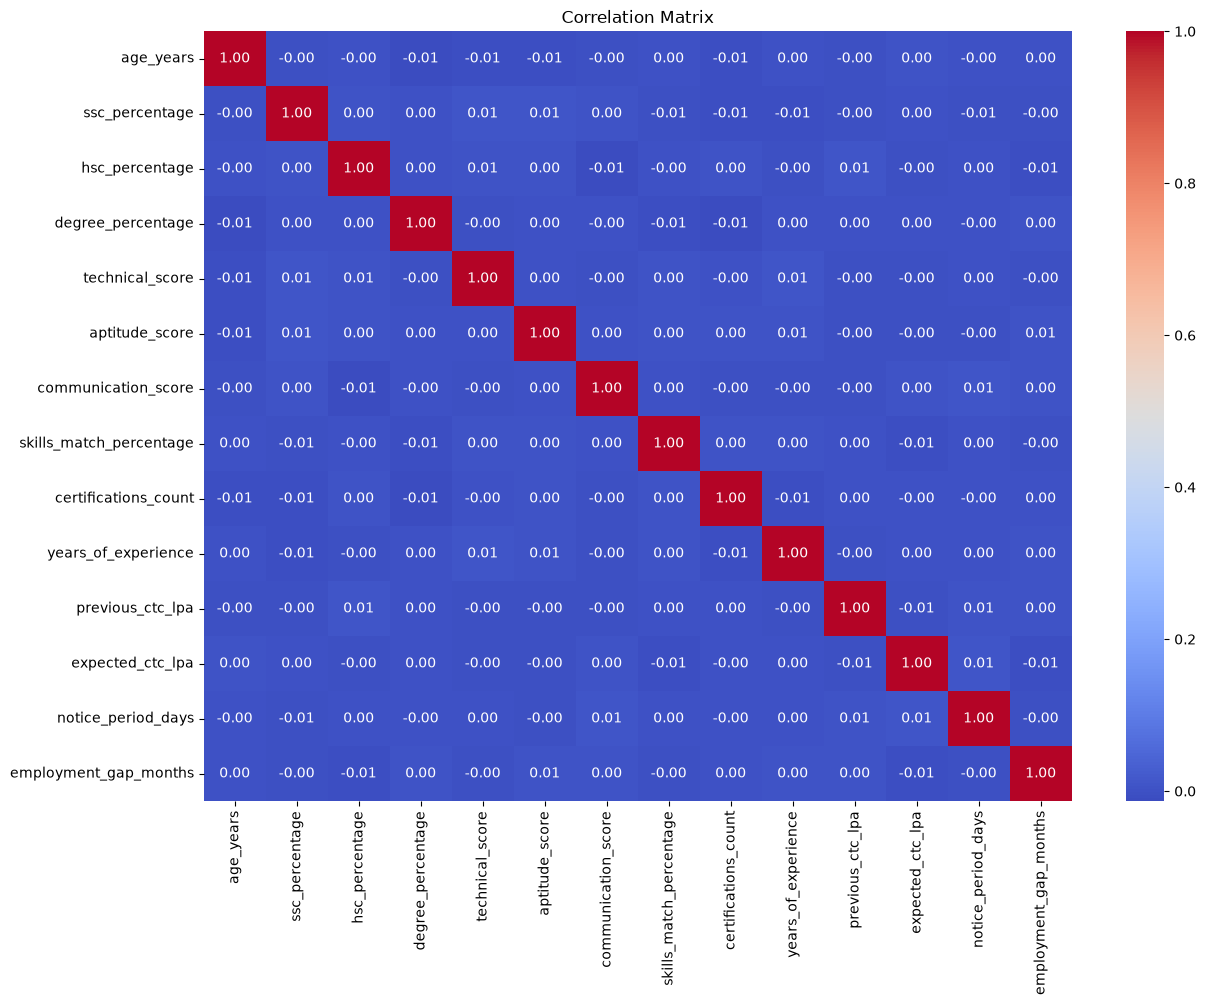

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_df = df_clean.select_dtypes(include="number")

plt.figure(figsize=(14, 10))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

In [26]:
df_clean["experience_category"] = pd.cut(
    df_clean["years_of_experience"],
    bins=[-1, 0, 2, float("inf")],
    labels=["Fresher", "Junior", "Senior"]
)

print(df_clean["experience_category"].value_counts())

experience_category
Junior     23474
Fresher    14952
Senior     11574
Name: count, dtype: int64


In [27]:
df_clean["academic_performance"] = pd.cut(
    df_clean["degree_percentage"],
    bins=[0, 60, 75, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print(df_clean["academic_performance"].value_counts())

academic_performance
Medium    26846
High      22078
Low        1076
Name: count, dtype: int64


In [28]:
df_clean["skills_match_level"] = pd.cut(
    df_clean["skills_match_percentage"],
    bins=[0, 60, 75, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print(df_clean["skills_match_level"].value_counts())

skills_match_level
High      23311
Medium    20484
Low        6205
Name: count, dtype: int64


In [29]:
df_clean["evaluation_score"] = df_clean[
    ["technical_score", "aptitude_score", "communication_score"]
].mean(axis=1)

df_clean["evaluation_performance"] = pd.cut(
    df_clean["evaluation_score"],
    bins=[0, 60, 75, 100],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print(df_clean["evaluation_performance"].value_counts())

evaluation_performance
Medium    38115
Low        8202
High       3683
Name: count, dtype: int64


In [30]:
df_clean[[
    "experience_category",
    "academic_performance",
    "skills_match_level",
    "evaluation_score",
    "evaluation_performance"
]].head()

,experience_category,academic_performance,skills_match_level,evaluation_score,evaluation_performance
0,Junior,High,High,70.754233,Medium
1,Fresher,Medium,Medium,62.532418,Medium
2,Junior,High,High,70.175622,Medium
3,Fresher,High,Medium,64.539376,Medium
4,Fresher,High,High,65.146274,Medium


In [31]:
df_clean.to_csv("HR_Job_Placement_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final Shape:", df_clean.shape)

Cleaned dataset saved successfully!
Final Shape: (50000, 31)


In [32]:
print("Dataset Shape:", df_clean.shape)

print("\nData Types:")
print(df_clean.dtypes)

Dataset Shape: (50000, 31)

Data Types:
age_years                       int64
gender                            str
ssc_percentage                float64
hsc_percentage                float64
degree_percentage             float64
degree_specialization             str
technical_score               float64
aptitude_score                float64
communication_score           float64
skills_match_percentage       float64
certifications_count            int64
internship_experience             str
years_of_experience             int64
career_switch_willingness         str
relevant_experience               str
previous_ctc_lpa              float64
expected_ctc_lpa              float64
company_tier                      str
job_role_match                    str
competition_level                 str
bond_requirement                  str
notice_period_days            float64
layoff_history                    str
employment_gap_months         float64
relocation_willingness            str
status    

In [33]:
categorical_columns = df_clean.select_dtypes(
    include=["str", "category"]
).columns.tolist()

print("Categorical Columns:")
print(categorical_columns)

print("\nTotal Categorical Columns:", len(categorical_columns))

Categorical Columns:
['gender', 'degree_specialization', 'internship_experience', 'career_switch_willingness', 'relevant_experience', 'company_tier', 'job_role_match', 'competition_level', 'bond_requirement', 'layoff_history', 'relocation_willingness', 'status', 'experience_category', 'academic_performance', 'skills_match_level', 'evaluation_performance']

Total Categorical Columns: 16


In [34]:
X = df_clean.drop("status", axis=1)
y = df_clean["status"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nTarget Distribution:")
print(y.value_counts())

Features Shape: (50000, 30)
Target Shape: (50000,)

Target Distribution:
status
Not Placed    34870
Placed        15130
Name: count, dtype: int64


In [35]:
y = y.map({
    "Not Placed": 0,
    "Placed": 1
})

print("Target Encoding Completed!")
print(y.value_counts())

Target Encoding Completed!
status
0    34870
1    15130
Name: count, dtype: int64


In [36]:
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print("Encoding Completed!")
print("Before Encoding:", X.shape)
print("After Encoding:", X_encoded.shape)

X_encoded.head()

Encoding Completed!
Before Encoding: (50000, 30)
After Encoding: (50000, 44)


,age_years,ssc_percentage,hsc_percentage,degree_percentage,technical_score,aptitude_score,communication_score,skills_match_percentage,certifications_count,years_of_experience,...,relocation_willingness_Unknown,relocation_willingness_Willing,experience_category_Junior,experience_category_Senior,academic_performance_Medium,academic_performance_High,skills_match_level_Medium,skills_match_level_High,evaluation_performance_Medium,evaluation_performance_High
0,27,65.061656,83.842578,75.856526,58.221909,89.566305,64.474484,79.548913,2,1,...,0,0,1,0,0,1,0,1,1,0
1,24,67.885626,64.973305,73.093588,71.927978,54.591971,61.077306,73.316134,1,0,...,0,0,0,0,1,0,1,0,1,0
2,33,73.892471,68.834121,90.196460,72.445041,58.587088,79.494739,75.466980,1,1,...,0,0,1,0,0,1,0,1,1,0
3,31,74.145568,76.255126,75.586731,78.855676,61.022065,53.740386,73.676449,2,0,...,1,0,0,0,0,1,1,0,1,0
4,28,60.475937,65.786336,80.801010,68.286776,65.713731,61.438314,88.994847,1,0,...,0,1,0,0,0,1,0,1,1,0


In [38]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.4 MB 2.1 MB/s eta 0:00:04
   ----- ---------------------------------- 1.0/8.4 MB 2.0 MB/s eta 0:00:04
   -------- ------------------------------- 1.8/8.4 MB 2.3 MB/s eta 0:00:03
   ----------- ---------------------------- 2.4/8.4 MB 2.4 MB/s eta 0:00:03
   ------------- -------------------------- 2.9/8.4 MB 2.5 MB/s eta 0:00:03
   ----------------- ---------------------- 3.7/8.4 MB 2.7 MB/s eta 0:00:02
   --------------------- ------------------ 4.5/8.4 MB 2.7 MB/s eta 0:00:02
   ------------------------- -------------- 5.2/8.4 MB 2.8 MB/s eta 0:00:02
   --------------------------- ------------ 5.8/8.4 MB 2.8 MB/s eta 0:00:01
   ------------------------------- -------- 6.6/8.4 MB 2.9 MB/s eta 0:00:01
   --------------------------------- ------ 7.1/8.4 MB 2.9 MB/s eta 0:00:01
   -----------------------


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\ELCOT\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [39]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (40000, 44)
Testing Features: (10000, 44)
Training Target: (40000,)
Testing Target: (10000,)


In [40]:
from sklearn.linear_model import LogisticRegression

log_model = LogisticRegression(max_iter=1000, random_state=42)

log_model.fit(X_train, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


C:\Users\ELCOT\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [41]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed!")
print("Training Shape:", X_train_scaled.shape)
print("Testing Shape:", X_test_scaled.shape)

Feature Scaling Completed!
Training Shape: (40000, 44)
Testing Shape: (10000, 44)


In [42]:
log_model = LogisticRegression(max_iter=3000, random_state=42)

log_model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully!")

Logistic Regression Model Trained Successfully!


In [43]:
y_pred_log = log_model.predict(X_test_scaled)

print("Prediction Completed!")

print("First 10 Actual Values:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred_log[:10])

Prediction Completed!
First 10 Actual Values:
[0 0 1 1 1 0 0 1 1 1]

First 10 Predicted Values:
[0 0 0 1 1 0 1 1 0 1]


In [44]:
from sklearn.metrics import accuracy_score

log_accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", log_accuracy * 100, "%")

Logistic Regression Accuracy: 88.14 %


In [45]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report:")
print(classification_report(
    y_test,
    y_pred_log,
    target_names=["Not Placed", "Placed"]
))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.91      0.93      0.92      6974
      Placed       0.82      0.78      0.80      3026

    accuracy                           0.88     10000
   macro avg       0.86      0.85      0.86     10000
weighted avg       0.88      0.88      0.88     10000



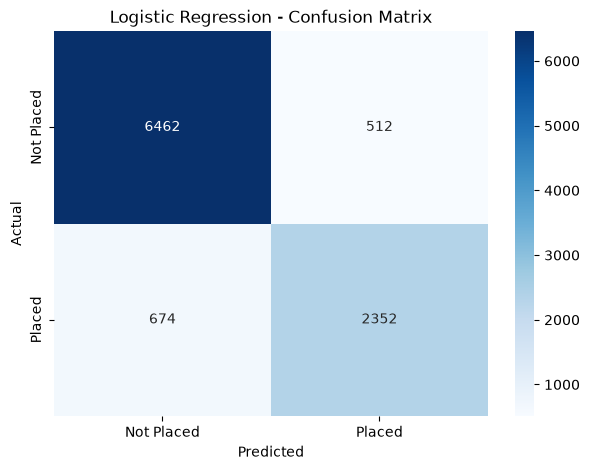

In [46]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_log)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Placed", "Placed"],
    yticklabels=["Not Placed", "Placed"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [47]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [48]:
y_pred_rf = rf_model.predict(X_test)

print("Random Forest Prediction Completed!")
print("First 10 Predictions:", y_pred_rf[:10])

Random Forest Prediction Completed!
First 10 Predictions: [0 0 0 1 1 0 0 1 1 1]


In [49]:
from sklearn.metrics import accuracy_score

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 88.9 %


In [50]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Not Placed", "Placed"]
))

              precision    recall  f1-score   support

  Not Placed       0.90      0.95      0.92      6974
      Placed       0.87      0.74      0.80      3026

    accuracy                           0.89     10000
   macro avg       0.88      0.85      0.86     10000
weighted avg       0.89      0.89      0.89     10000



In [51]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [log_accuracy * 100, rf_accuracy * 100]
})

model_comparison

,Model,Accuracy
0,Logistic Regression,88.14
1,Random Forest,88.90


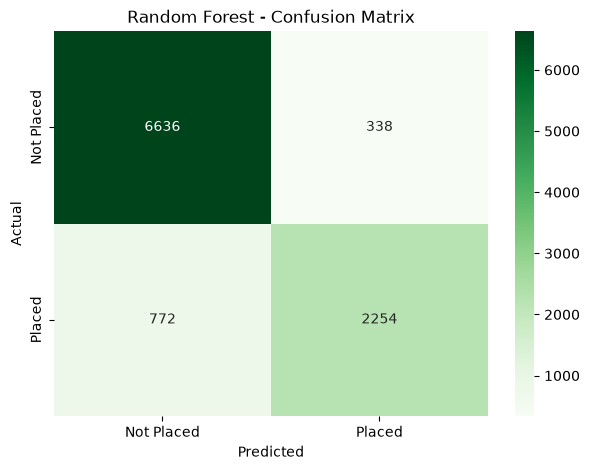

In [52]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm_rf = confusion_matrix(y_test, y_pred_rf)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Not Placed", "Placed"],
    yticklabels=["Not Placed", "Placed"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Random Forest - Confusion Matrix")
plt.show()

In [53]:
feature_importance = pd.DataFrame({
    "Feature": X_encoded.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
4,technical_score,0.173801
14,evaluation_score,0.080735
9,years_of_experience,0.073131
7,skills_match_percentage,0.068441
11,expected_ctc_lpa,0.060756
37,experience_category_Senior,0.043296
10,previous_ctc_lpa,0.042471
6,communication_score,0.037454
5,aptitude_score,0.036412
27,job_role_match_Not Matched,0.034580


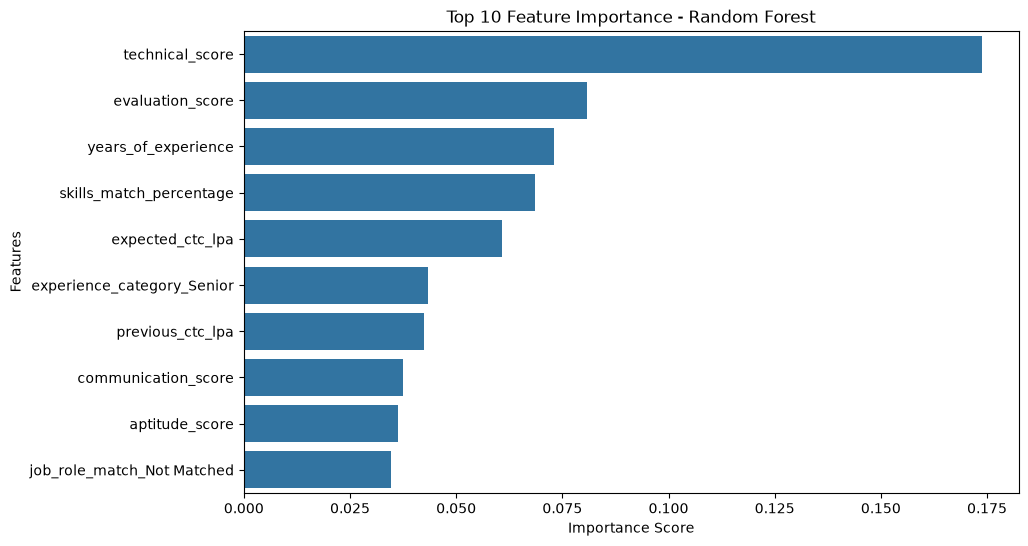

In [54]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

In [55]:
import joblib

joblib.dump(rf_model, "random_forest_model.pkl")
joblib.dump(scaler, "standard_scaler.pkl")

print("ML Models Saved Successfully!")

ML Models Saved Successfully!


In [56]:
joblib.dump(X_encoded.columns.tolist(), "model_features.pkl")

print("Model Features Saved Successfully!")

Model Features Saved Successfully!


In [57]:
import mysql.connector
from getpass import getpass

connection = mysql.connector.connect(
    host="localhost",
    user="root",
    password=getpass("Enter MySQL password: "),
    database="job_acceptance_db"
)

print("MySQL Connected Successfully!")

Enter MySQL password:  ········


MySQL Connected Successfully!


In [58]:
cursor = connection.cursor()

print("Database cursor created successfully!")

Database cursor created successfully!


In [59]:
df_sql = pd.read_csv("HR_Job_Placement_Cleaned.csv")

print("Dataset loaded for MySQL!")
print("Shape:", df_sql.shape)

Dataset loaded for MySQL!
Shape: (50000, 31)


In [60]:
print("CSV Columns:", len(df_sql.columns))
print("MySQL Table Columns: 31")
print("Ready to insert 50,000 records!")

CSV Columns: 31
MySQL Table Columns: 31
Ready to insert 50,000 records!


In [61]:
import numpy as np

df_insert = df_sql.astype(object).where(pd.notna(df_sql), None)

columns = ", ".join(f"`{col}`" for col in df_sql.columns)
placeholders = ", ".join(["%s"] * len(df_sql.columns))

insert_query = f"""
INSERT INTO job_placement_data ({columns})
VALUES ({placeholders})
"""

data = [
    tuple(None if pd.isna(value) else value for value in row)
    for row in df_insert.itertuples(index=False, name=None)
]

cursor.executemany(insert_query, data)
connection.commit()

print("Total rows inserted:", cursor.rowcount)
print("Data inserted successfully!")

Total rows inserted: 50000
Data inserted successfully!


In [62]:
cursor.execute("SELECT COUNT(*) FROM job_placement_data")

total_rows = cursor.fetchone()[0]

print("Total rows in MySQL:", total_rows)

Total rows in MySQL: 50000
